Kaggle API key upload etc.

In [ ]:
from google.colab import files
files.upload()  # upload kaggle.json for the API key

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"arwanmakhija","key":"cbd7c0598fe7f5907fa9dafde04a9e07"}'}

Kaggle API credential loading etc.

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Download Assets/dataset

In [ ]:
!pip install -q kaggle librosa tensorflow scikit-learn
!kaggle datasets download andradaolteanu/gtzan-dataset-music-genre-classification
!unzip -q gtzan-dataset-music-genre-classification.zip -d ./GTZAN

Dataset URL: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification
License(s): other
 98% 1.19G/1.21G [00:07<00:00, 91.7MB/s]
100% 1.21G/1.21G [00:07<00:00, 178MB/s] 


Importing Libraries

In [ ]:
!pip install librosa tensorflow scikit-learn pysptk

import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models
import pysptk

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.9/461.9 kB 7.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pysptk: filename=pysptk-1.0.1-cp311-cp311-linux_x86_64.whl size=1373955 sha256=e4eb31cbdaa1786c77aeea648c585034fe5382386366c352153732b301d4662c
  Stored in directory: /root/.cache/pip/wheels/f7/8e/e6/be2295ab3cba2d52e826922cd3ea8bda4a18210c03584dc759
Successfully built pysptk


Feature Extraction for all features

In [ ]:
# Individual feature extractors


def extract_mfcc(y, sr):
    return librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

def extract_delta(y, sr):
    mfcc = extract_mfcc(y, sr)
    return librosa.feature.delta(mfcc)

def extract_spectral(y, sr):
    return librosa.feature.spectral_centroid(y=y, sr=sr)

def extract_combined(y, sr):
    mfcc = extract_mfcc(y, sr)
    delta = librosa.feature.delta(mfcc)
    cent = extract_spectral(y, sr)
    return np.vstack((mfcc, delta, cent))

def extract_lsp(y, sr, order=12):
    frame_length = 512
    hop_length = 256
    frames = librosa.util.frame(y, frame_length=frame_length, hop_length=hop_length).T
    lsp_list = []
    for frame in frames:
        if np.all(frame == 0): continue
        try:
            lpc = pysptk.lpc(frame.astype(np.float64), order)
            lsp = pysptk.lpc2lsp(lpc)
            lsp_list.append(lsp)
        except Exception:
            continue
    return np.array(lsp_list).T if lsp_list else np.zeros((order, 1))

Process Dataset

In [ ]:
def process_dataset(feature_fn, genres, path, max_len=130):
    X, y = [], []
    for label, genre in enumerate(genres):
        folder = os.path.join(path, genre)
        for file in os.listdir(folder):
            if file.endswith(".wav"):
                try:
                    y_audio, sr = librosa.load(os.path.join(folder, file), duration=30)
                    features = feature_fn(y_audio, sr)

                    # Reshape 1D features to be (features, timesteps) before padding
                    if features.ndim == 1:
                        features = features.reshape(1, -1)

                    if features.shape[1] >= max_len:
                        features = features[:, :max_len]
                    else:
                        pad_width = max_len - features.shape[1]
                        features = np.pad(features, ((0, 0), (0, pad_width)))

                    X.append(features)
                    y.append(label)
                except Exception as e:
                    print(f"Failed on {file}: {e}")     #Jazz.00054 always does not work

    X = np.array(X)

    # Ensure 1D features are explicitly reshaped to (samples, timesteps, 1)
    if X.ndim == 3 and X.shape[1] == 1:
        X = X.reshape(X.shape[0], X.shape[2], 1)
    elif X.ndim == 2: # Handle cases where padding resulted in 2D array and reshape for Conv1D
         X = X.reshape(X.shape[0], X.shape[1], 1)
    elif X.ndim == 3 and X.shape[1] > 1: # For 2D features, add the channel dimension
        X = X[..., np.newaxis]


    X = X / np.max(np.abs(X))  # normalize
    y = np.array(y)
    return X, y

Model Structure

In [ ]:
def build_model(input_shape):
    model = models.Sequential()

    # Check if the input shape is suitable for Conv1D ((timesteps, 1) or just (timesteps,))
    # Features like Spectral Centroid and LSP will be 1D (after processing), w/ shape (samples, timesteps, 1)
    # MFCC, Delta, and Combined will be 2D features, w/ in shape (samples, features, timesteps, 1)
    if len(input_shape) == 2 or (len(input_shape) == 3 and input_shape[-1] == 1 and input_shape[0] != 13 and input_shape[0] != 26 and input_shape[0] != 27): # Heuristics to differentiate 1D-like processed data from 2D features
        print(f"Building Conv1D model with input shape: {input_shape}")
        model.add(layers.Conv1D(32, 3, activation='relu', input_shape=input_shape))
        model.add(layers.MaxPooling1D(2))
        model.add(layers.Dropout(0.25))
        model.add(layers.Conv1D(64, 3, activation='relu'))
        model.add(layers.MaxPooling1D(2))
        model.add(layers.Dropout(0.25))
        model.add(layers.Flatten())
        model.add(layers.Dense(128, activation='relu'))
        model.add(layers.Dropout(0.5))
        model.add(layers.Dense(10, activation='softmax'))  # classifies 10 genres
    else: #  2D features like MFCC, Delta, and Combined w/ shape (features, timesteps, 1)
        print(f"Building Conv2D model with input shape: {input_shape}")
        model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Dropout(0.25))
        model.add(layers.Conv2D(64, (3, 3), activation='relu'))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Dropout(0.25))
        model.add(layers.Flatten())
        model.add(layers.Dense(128, activation='relu'))
        model.add(layers.Dropout(0.5))
        model.add(layers.Dense(10, activation='softmax'))  # classifies 10 genres


    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

Training and evaluation

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models
import seaborn as sns # Import seaborn

def train_and_evaluate(X, y, title):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = build_model(X_train.shape[1:])
    print(f"\n Model Summary for {title}")
    model.summary()
    print(f"\n Training {title} ...")
    history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test), verbose=0)

    y_probs = model.predict(X_test)
    y_pred = np.argmax(y_probs, axis=1)

    print(f"\n Evaluation Metrics for {title}")
    print(classification_report(y_test, y_pred, target_names=genres))
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f" Precision: {precision:.4f}")
    print(f" Recall:    {recall:.4f}")
    print(f" F1 Score:  {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 7)) # Increased figure size for better readability
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=genres, yticklabels=genres) # Use seaborn for heatmap with genre labels
    plt.title(f"{title} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    # Training Graphs
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f"{title} - Accuracy")
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f"{title} - Loss")
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

    return {
        "title": title,
        "accuracy": history.history['val_accuracy'][-1],
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Run all models

/tmp/ipython-input-2397153676.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y_audio, sr = librosa.load(os.path.join(folder, file), duration=30)
/usr/local/lib/python3.11/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Failed on jazz.00054.wav: 
Building Conv2D model with input shape: (13, 130, 1)

 Model Summary for MFCC Only


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 11, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 5, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 3, 62, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1984)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       254,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 274,186 (1.05 MB)

 Trainable params: 274,186 (1.05 MB)

 Non-trainable params: 0 (0.00 B)


 Training MFCC Only ...
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

 Evaluation Metrics for MFCC Only
              precision    recall  f1-score   support

       blues       0.29      0.29      0.29        21
   classical       0.80      0.67      0.73        12
     country       0.17      0.12      0.14        24
       disco       0.33      0.05      0.08        22
      hiphop       0.26      0.33      0.29        15
        jazz       0.53      0.30      0.38        27
       metal       0.53      0.94      0.68        18
         pop       0.38      0.84      0.52        19
      reggae       0.43      0.59      0.50        22
        rock       0.30      0.15      0.20        20

    accuracy                           0.40       200
   macro avg       0.40      0.43      0.38       200
weighted avg       0.39      0.40      0.36       200

 Precision: 0.3881
 Recall:    0.4000
 F1 Score:  0.3591


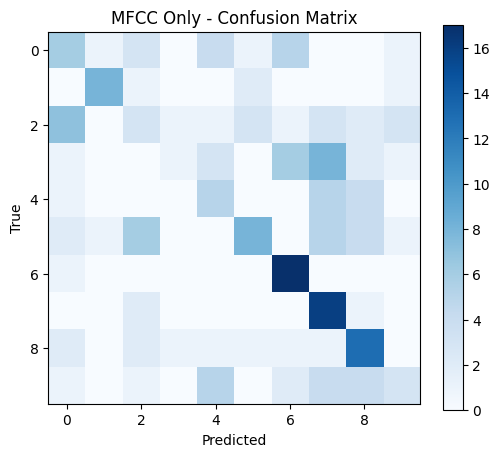

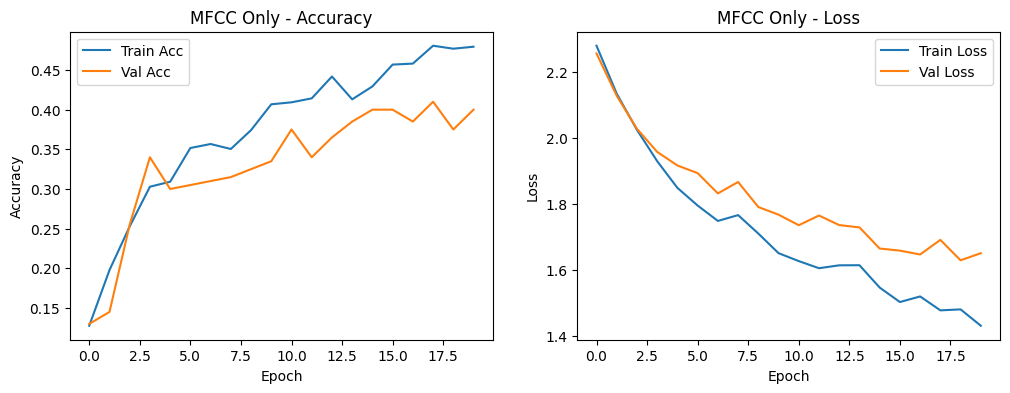

/tmp/ipython-input-2397153676.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y_audio, sr = librosa.load(os.path.join(folder, file), duration=30)
/usr/local/lib/python3.11/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Failed on jazz.00054.wav: 
Building Conv2D model with input shape: (13, 130, 1)

 Model Summary for Delta Only


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 11, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 5, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 62, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1984)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       254,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 274,186 (1.05 MB)

 Trainable params: 274,186 (1.05 MB)

 Non-trainable params: 0 (0.00 B)


 Training Delta Only ...
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step

 Evaluation Metrics for Delta Only
              precision    recall  f1-score   support

       blues       0.33      0.24      0.28        21
   classical       0.42      0.67      0.52        12
     country       0.29      0.38      0.33        24
       disco       0.29      0.18      0.22        22
      hiphop       0.23      0.73      0.35        15
        jazz       0.52      0.48      0.50        27
       metal       0.38      0.61      0.47        18
         pop       0.50      0.11      0.17        19
      reggae       0.00      0.00      0.00        22
        rock       0.15      0.10      0.12        20

    accuracy                           0.33       200
   macro avg       0.31      0.35      0.30       200
weighted avg       0.31      0.33      0.29       200

 Precision: 0.3113
 Recall:    0.3250
 F1 Score:  0.2887


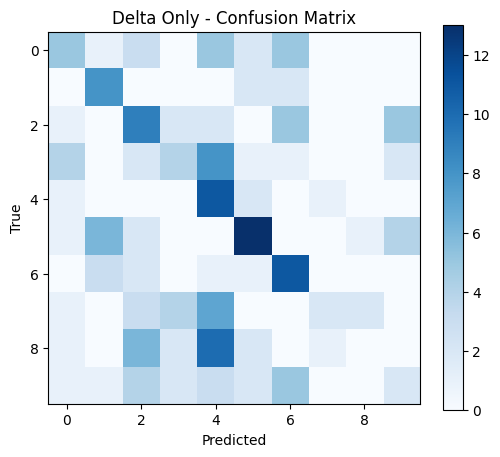

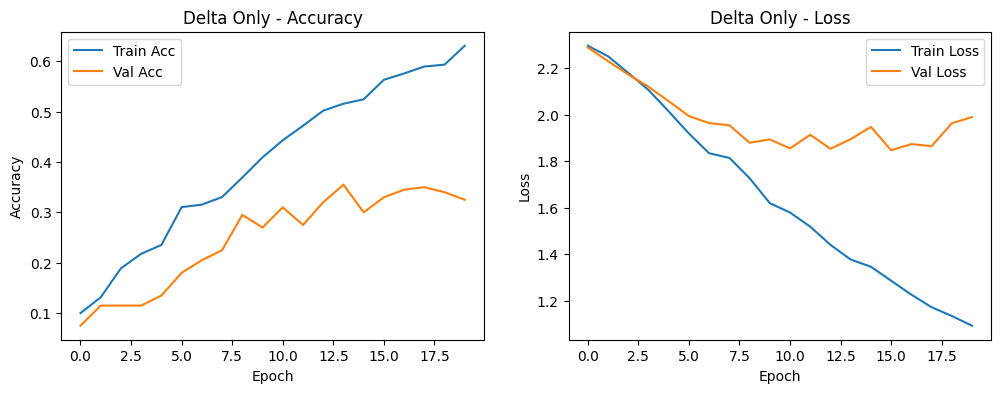

/tmp/ipython-input-2397153676.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y_audio, sr = librosa.load(os.path.join(folder, file), duration=30)
/usr/local/lib/python3.11/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Failed on jazz.00054.wav: 
Building Conv1D model with input shape: (130, 1)

 Model Summary for Spectral Centroid


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 62, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 31, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 31, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1984)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       254,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 261,706 (1022.29 KB)

 Trainable params: 261,706 (1022.29 KB)

 Non-trainable params: 0 (0.00 B)


 Training Spectral Centroid ...


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

 Evaluation Metrics for Spectral Centroid
              precision    recall  f1-score   support

       blues       0.25      0.24      0.24        21
   classical       0.38      1.00      0.55        12
     country       0.40      0.25      0.31        24
       disco       0.21      0.14      0.17        22
      hiphop       0.36      0.27      0.31        15
        jazz       0.33      0.04      0.07        27
       metal       0.38      0.89      0.53        18
         pop       0.55      0.58      0.56        19
      reggae       0.33      0.45      0.38        22
        rock       0.31      0.20      0.24        20

    accuracy                           0.36       200
   macro avg       0.35      0.41      0.34       200
weighted avg       0.35      0.36      0.31       200

 Precision: 0.3466
 Recall:    0.3600
 F1 Score:  0.3138


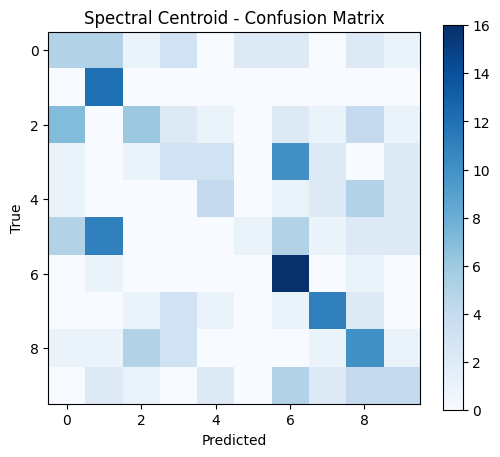

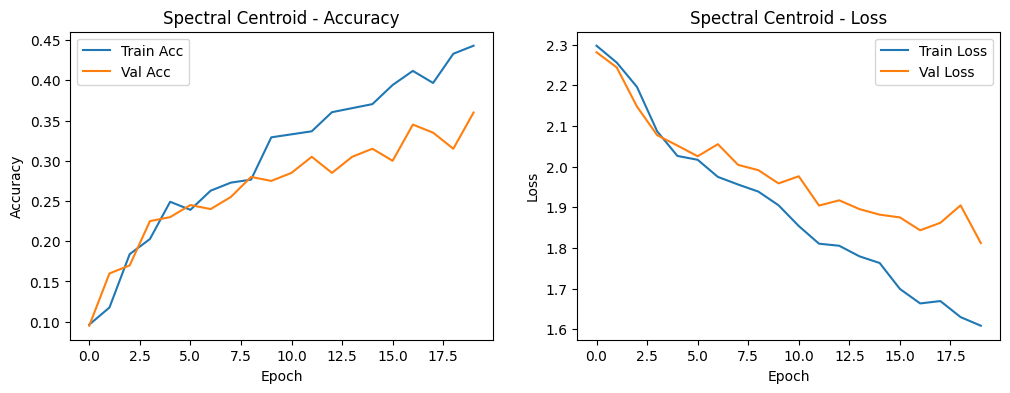

/tmp/ipython-input-2397153676.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y_audio, sr = librosa.load(os.path.join(folder, file), duration=30)
/usr/local/lib/python3.11/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Failed on jazz.00054.wav: 
Building Conv2D model with input shape: (13, 130, 1)

 Model Summary for LSP (Line Spectral Pairs)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 11, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 5, 64, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 62, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1984)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       254,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 274,186 (1.05 MB)

 Trainable params: 274,186 (1.05 MB)

 Non-trainable params: 0 (0.00 B)


 Training LSP (Line Spectral Pairs) ...


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

 Evaluation Metrics for LSP (Line Spectral Pairs)
              precision    recall  f1-score   support

       blues       0.25      0.24      0.24        21
   classical       0.35      0.92      0.51        12
     country       0.00      0.00      0.00        24
       disco       0.20      0.14      0.16        22
      hiphop       0.18      0.53      0.27        15
        jazz       0.23      0.11      0.15        27
       metal       0.29      0.22      0.25        18
         pop       0.52      0.63      0.57        19
      reggae       0.35      0.32      0.33        22
        rock       0.11      0.05      0.07        20

    accuracy                           0.27       200
   macro avg       0.25      0.32      0.26       200
weighted avg       0.24      0.27      0.24       200

 Precision: 0.2392
 Recall:    0.2700
 F1 Score:  0.2351


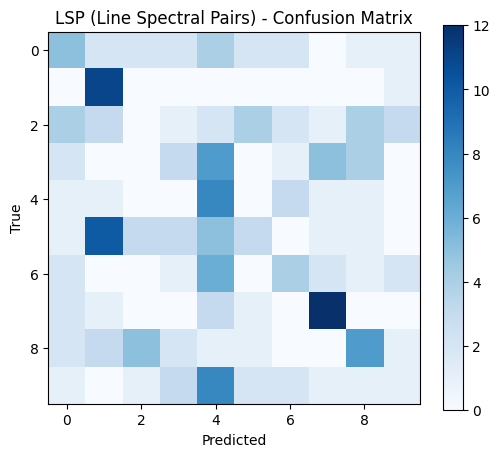

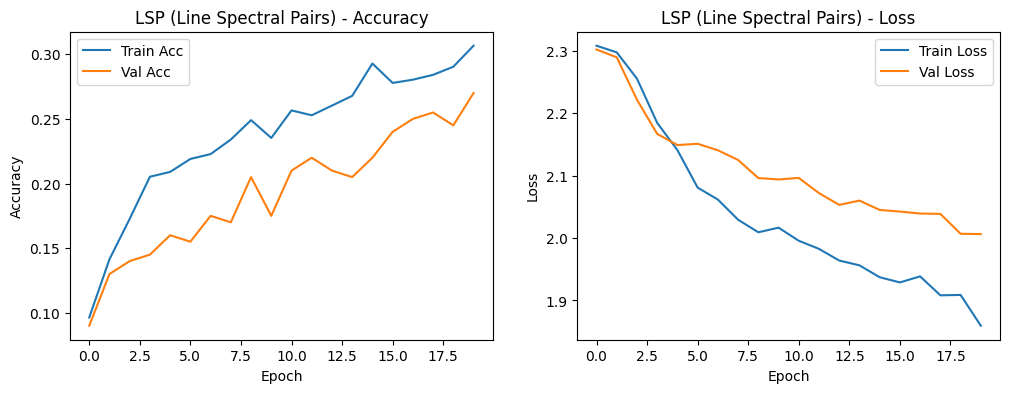

/tmp/ipython-input-2397153676.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y_audio, sr = librosa.load(os.path.join(folder, file), duration=30)
/usr/local/lib/python3.11/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Failed on jazz.00054.wav: 
Building Conv2D model with input shape: (27, 130, 1)

 Model Summary for MFCC + Delta + Spectral (Combined)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 25, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 12, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 12, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 5, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 9920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     1,269,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,289,994 (4.92 MB)

 Trainable params: 1,289,994 (4.92 MB)

 Non-trainable params: 0 (0.00 B)


 Training MFCC + Delta + Spectral (Combined) ...
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step

 Evaluation Metrics for MFCC + Delta + Spectral (Combined)
              precision    recall  f1-score   support

       blues       0.00      0.00      0.00        21
   classical       0.33      0.83      0.48        12
     country       0.30      0.25      0.27        24
       disco       0.00      0.00      0.00        22
      hiphop       0.50      0.07      0.12        15
        jazz       0.19      0.11      0.14        27
       metal       0.19      0.83      0.31        18
         pop       0.00      0.00      0.00        19
      reggae       0.23      0.27      0.25        22
        rock       0.18      0.25      0.21        20

    accuracy                           0.23       200
   macro avg       0.19      0.26      0.18       200
weighted avg       0.18      0.23      0.17       200

 Precision: 0.1794
 Recall:    0.2300
 F1 Score:  0.1654


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/m

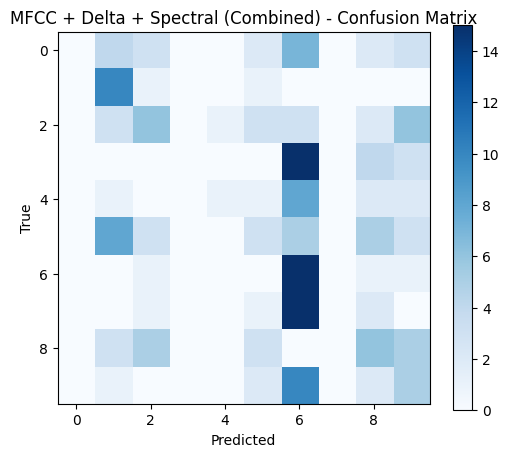

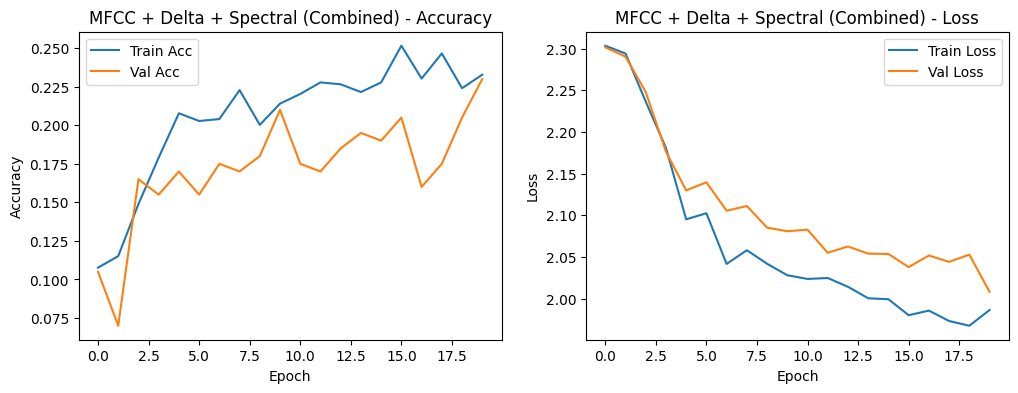

In [ ]:
genres = 'blues classical country disco hiphop jazz metal pop reggae rock'.split()
base_path = "/content/GTZAN/Data/genres_original"

results = []

X_mfcc, y_mfcc = process_dataset(extract_mfcc, genres, base_path)
results.append(train_and_evaluate(X_mfcc, y_mfcc, "MFCC Only"))

X_delta, y_delta = process_dataset(extract_delta, genres, base_path)
results.append(train_and_evaluate(X_delta, y_delta, "Delta Only"))

X_spec, y_spec = process_dataset(extract_spectral, genres, base_path)
results.append(train_and_evaluate(X_spec, y_spec, "Spectral Centroid"))

X_lsp, y_lsp = process_dataset(extract_lsp, genres, base_path)
results.append(train_and_evaluate(X_lsp, y_lsp, "LSP (Line Spectral Pairs)"))

X_comb, y_comb = process_dataset(extract_combined, genres, base_path)
results.append(train_and_evaluate(X_comb, y_comb, "MFCC + Delta + Spectral (Combined)"))
